**Parte 1**

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.special import jv

In [3]:
pi = np.pi
lamb = 1
a = 50*lamb
k = 2*pi/lamb

num = 181

theta = np.linspace(-pi/18, pi/2, 1442) #721
phi   = np.linspace(0, pi/2, 181)

# --- grades finas o bastante para ka ~ 314 ---
Nrho = 1001                                   # ímpar, para Simpson                          
Nphp = 1024  # pontos em phi' (periódico)
rho_l = np.linspace(0, a, Nrho)
phi_l = np.linspace(0, 2*np.pi, Nphp, endpoint=False)

# --- integral numérica, só para phi = 0 (I não depende de phi) ---
I_th = np.zeros(len(theta), dtype=complex)
RHO  = rho_l[:, None]
COS  = np.cos(phi_l)[None, :]                 # cos(0 - phi')

for i, th in enumerate(theta):
    integrando = RHO * np.exp(1j*k*RHO*np.sin(th)*COS)     # (rho', phi')
    Iphi = integrando.mean(axis=1) * 2*np.pi                  # trapézio periódico em phi'
    I_th[i] = simpson(Iphi, x=rho_l)                          # Simpson em rho'

# --- campos: broadcasting, I é independente de phi ---
TH, PH = np.meshgrid(theta, phi, indexing='ij')
I = I_th[:, None]

E_theta =  np.cos(TH)*np.cos(PH)*I
E_phi   = -np.sin(PH)*I

norm = max(np.abs(E_theta).max(), np.abs(E_phi).max())        # mesmo máximo para as duas
E_theta = 20*np.log10(np.abs(E_theta)/norm + 1e-12)
E_phi   = 20*np.log10(np.abs(E_phi)/norm + 1e-12)

Solução Analítica

In [4]:
num2 = 2000  ### Número de pontos
theta2 = np.linspace(-pi/18,pi,num2)
phi2 = np.linspace(0,pi/2,num2)

TH, PH = np.meshgrid(theta2, phi2, indexing='ij')

u = k*np.sin(theta2)          # vetor em theta
x = u*a

# --- Caso A: peso rho' ---
I_theta = np.where(np.abs(x) > 1e-8,
                   2*np.pi*a*jv(1, x)/np.where(np.abs(x) > 1e-8, u, 1),
                   np.pi*a**2)                  # limite em u -> 0

I = np.tile(I_theta[:, None], (1, num2))         # I[theta, phi], independe de phi

Ea_theta =  np.cos(TH)*np.cos(PH)*I
Ea_phi   = -np.sin(PH)*I

norm = np.max(np.abs(Ea_theta))                 # ou max das duas componentes
Ea_theta = 20*np.log10(np.abs(Ea_theta)/norm + 1e-12)
Ea_phi   = 20*np.log10(np.abs(Ea_phi)/norm + 1e-12)


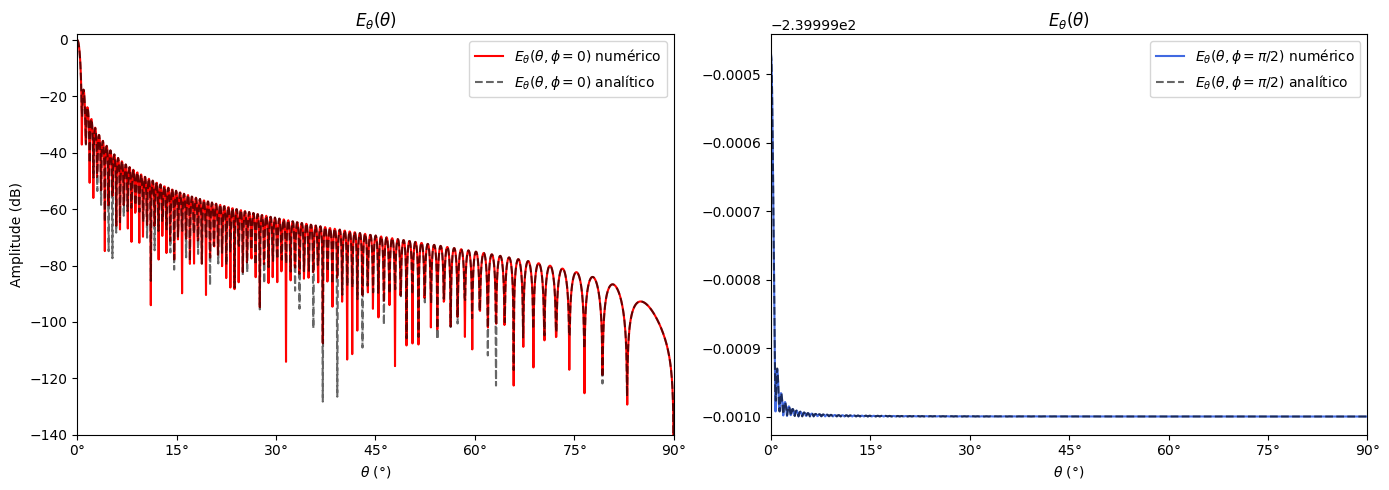

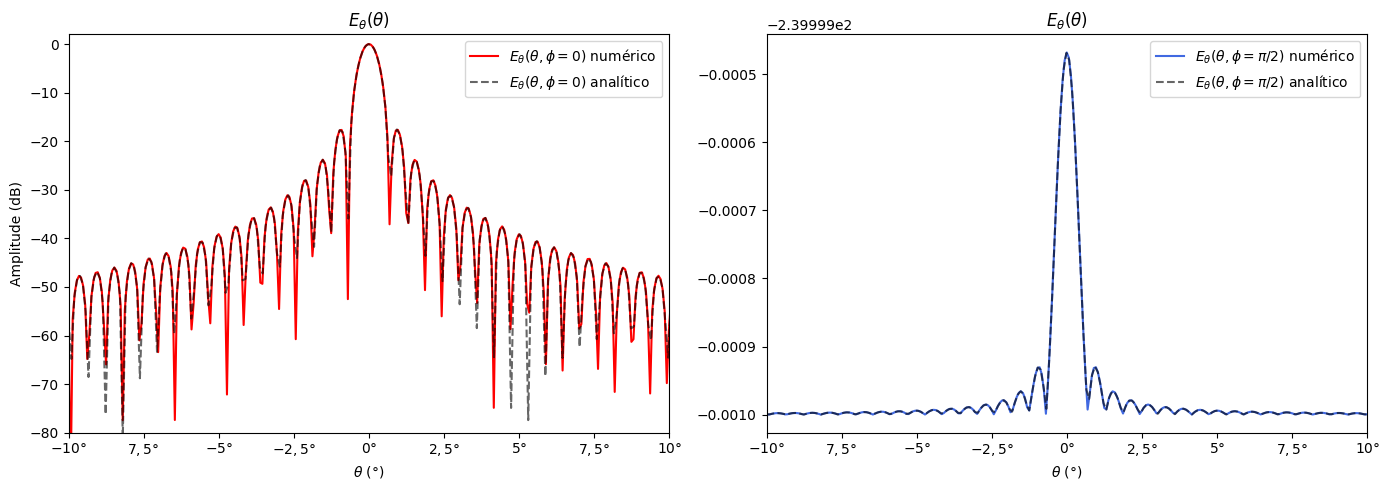

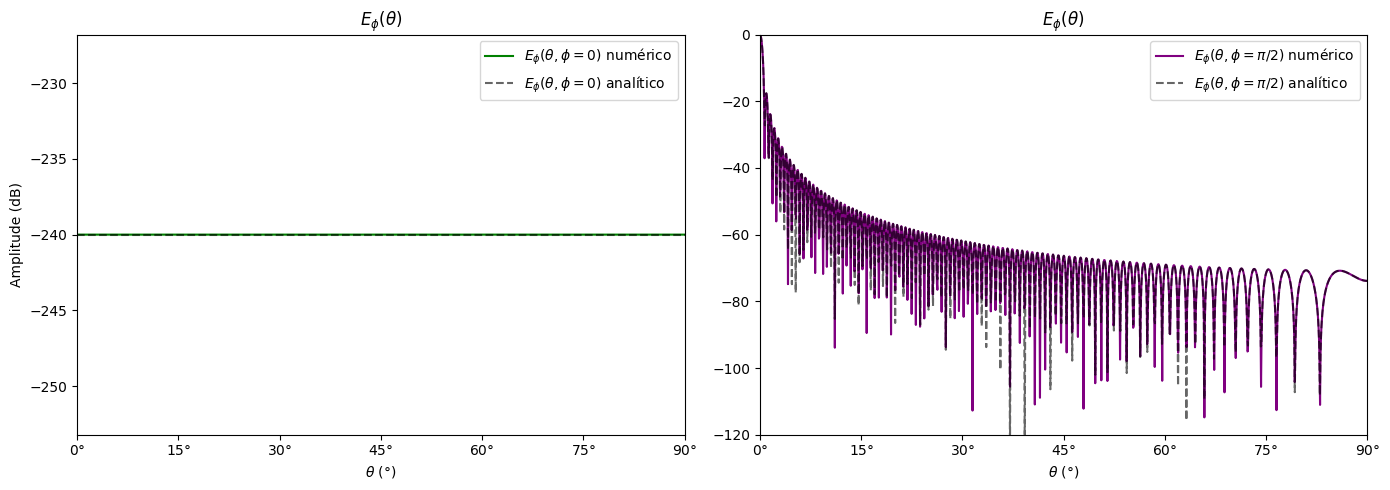

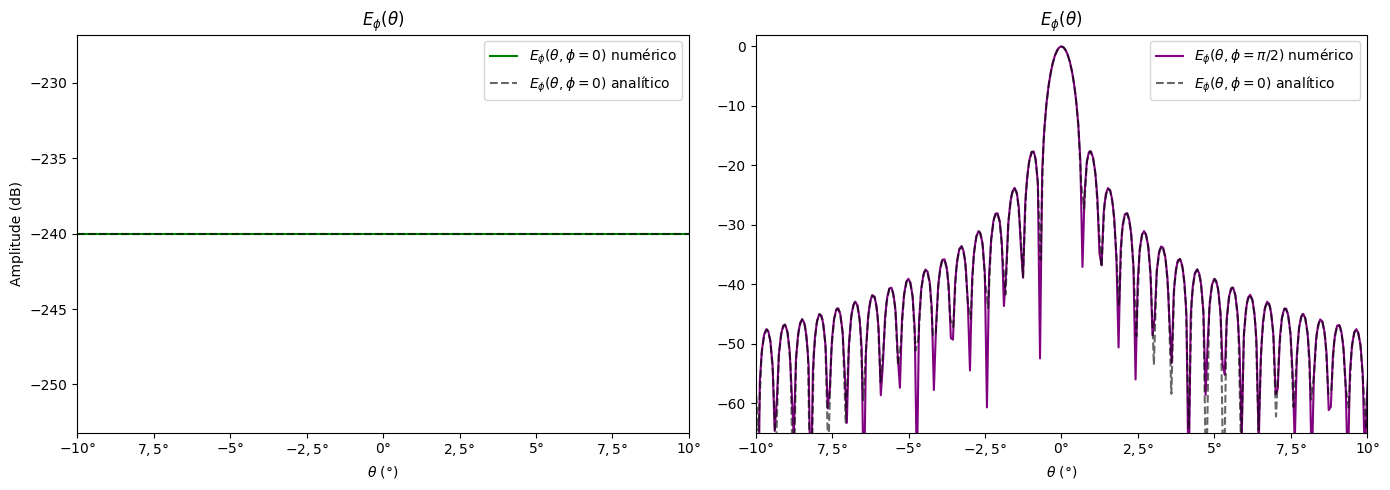

In [15]:
fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\theta(\theta)$')
ax[1].set_title(r'$E_\theta(\theta)$')

ax[0].plot(theta,np.real(E_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ numérico',color='red')
ax[0].plot(theta2,np.real(Ea_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)

ax[1].plot(theta,np.real(E_theta[:,-1]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
ax[1].plot(theta2,np.real(Ea_theta[:,-1]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)

for i in [0,1]:
    ax[i].set_xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                     [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
    ax[i].set_xlim(0,pi/2)
    ax[i].set_xlabel(r'$\theta$ (°)')
    ax[i].legend()

ax[0].set_ylim(-140,2)
ax[0].set_ylabel('Amplitude (dB)')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\theta(\theta)$')
ax[1].set_title(r'$E_\theta(\theta)$')

ax[0].plot(theta,np.real(E_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ numérico',color='red')
ax[0].plot(theta2,np.real(Ea_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)

ax[1].plot(theta,np.real(E_theta[:,-1]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
ax[1].plot(theta2,np.real(Ea_theta[:,-1]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)

for i in [0,1]:
    ax[i].set_xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                     [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
    ax[i].set_xlim(-pi/18,pi/18)
    #ax[i].set_ylim(-65,2)
    ax[i].set_xlabel(r'$\theta$ (°)')
    ax[i].legend()

ax[0].set_ylim(-80,2)
ax[0].set_ylabel('Amplitude (dB)')

plt.tight_layout()
plt.show()


fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\phi(\theta)$')
ax[1].set_title(r'$E_\phi(\theta)$')

ax[0].plot(theta,np.real(E_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ numérico',color='green')
ax[0].plot(theta2,np.real(Ea_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)

ax[1].plot(theta,np.real(E_phi[:,-1]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$ numérico',color='purple')
ax[1].plot(theta2,np.real(Ea_phi[:,-1]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)

for i in [0,1]:
    ax[i].set_xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                     [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
    ax[i].set_xlim(0,pi/2)
    ax[i].legend()
    ax[i].set_xlabel(r'$\theta$ (°)')

ax[0].set_ylabel('Amplitude (dB)')
ax[1].set_ylim(-120,0)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\phi(\theta)$')
ax[1].set_title(r'$E_\phi(\theta)$')

ax[0].plot(theta,np.real(E_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ numérico',color='green')
ax[0].plot(theta2,np.real(Ea_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)

ax[1].plot(theta,np.real(E_phi[:,-1]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$ numérico',color='purple')
ax[1].plot(theta2,np.real(Ea_phi[:,-1]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)

for i in [0,1]:
    ax[i].set_xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                     [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
    ax[i].set_xlim(-pi/18,pi/18)
    ax[i].set_xlabel(r'$\theta$ (°)')
    ax[i].legend()

ax[1].set_ylim(-65,2)
ax[0].set_ylabel('Amplitude (dB)')

plt.tight_layout()
plt.show()

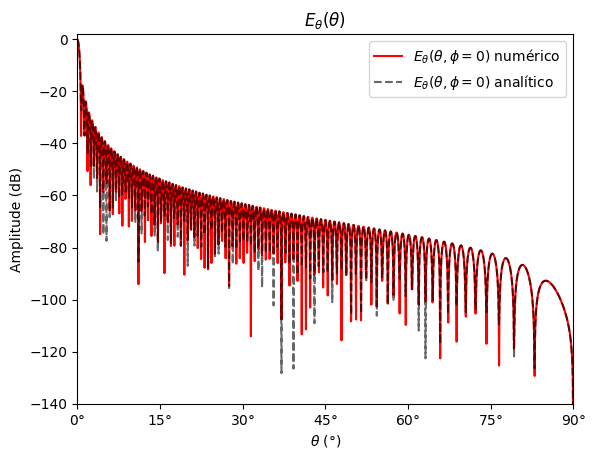

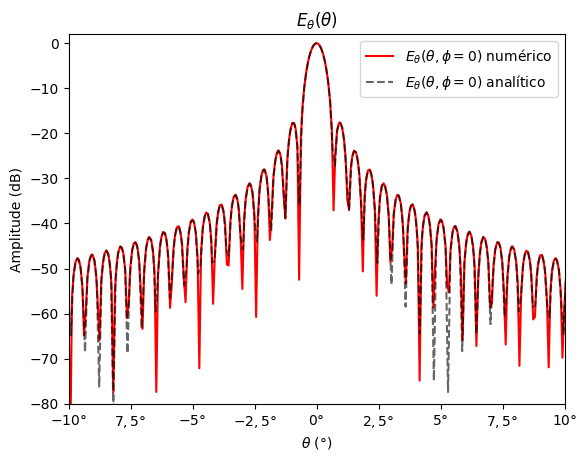

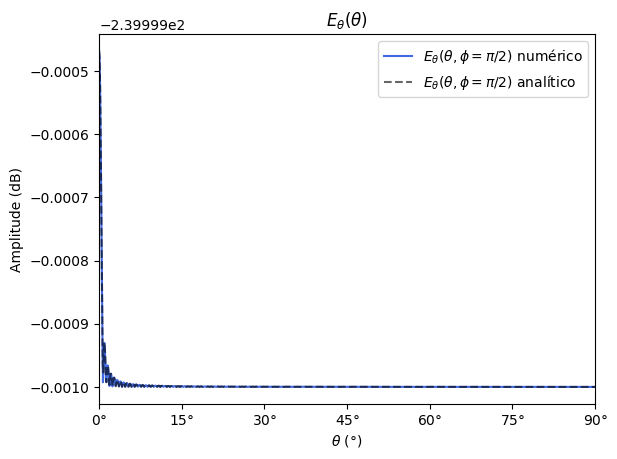

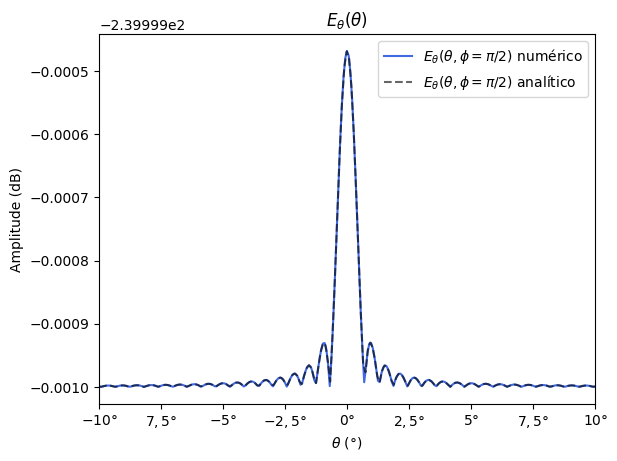

In [16]:
plt.figure()
plt.title(r'$E_\theta(\theta)$')
plt.plot(theta,np.real(E_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ numérico',color='red')
plt.plot(theta2,np.real(Ea_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                     [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
plt.xlim(0,pi/2)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylim(-140,2)
plt.ylabel('Amplitude (dB)')
plt.show()

plt.figure()
plt.title(r'$E_\theta(\theta)$')
plt.plot(theta,np.real(E_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ numérico',color='red')
plt.plot(theta2,np.real(Ea_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                    [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
plt.xlim(-pi/18,pi/18)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylim(-80,2)
plt.ylabel('Amplitude (dB)')
plt.show()

plt.figure()
plt.title(r'$E_\theta(\theta)$')
plt.plot(theta,np.real(E_theta[:,-1]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
plt.plot(theta2,np.real(Ea_theta[:,-1]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                    [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
plt.xlim(0,pi/2)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylabel('Amplitude (dB)')
plt.show()

plt.figure()
plt.title(r'$E_\theta(\theta)$')
plt.plot(theta,np.real(E_theta[:,-1]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
plt.plot(theta2,np.real(Ea_theta[:,-1]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                    [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
plt.xlim(-pi/18,pi/18)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylabel('Amplitude (dB)')
plt.show()

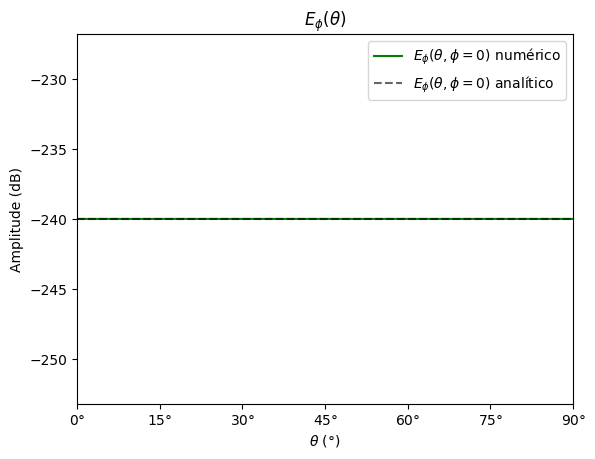

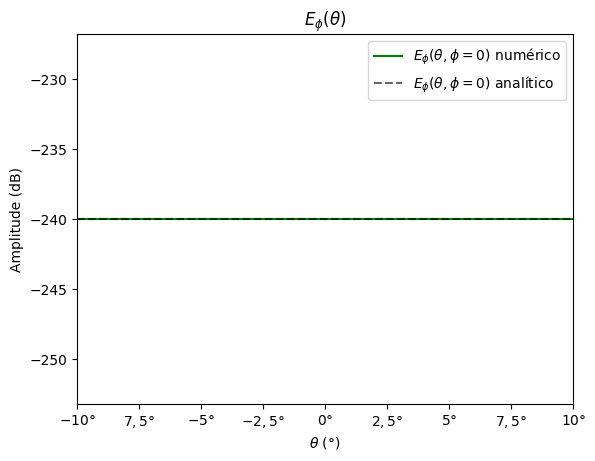

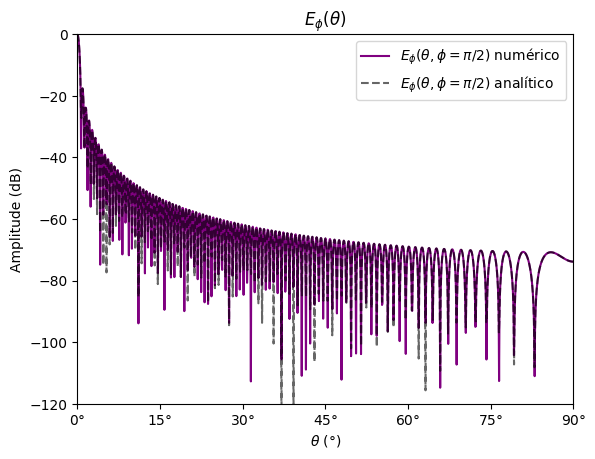

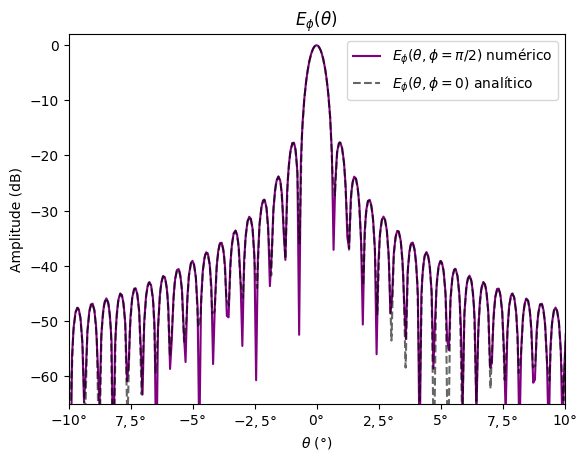

In [17]:
plt.figure()
plt.title(r'$E_\phi(\theta)$')
plt.plot(theta,np.real(E_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ numérico',color='green')
plt.plot(theta2,np.real(Ea_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                    [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
plt.xlim(0,pi/2)
plt.legend()
plt.xlabel(r'$\theta$ (°)')
plt.ylabel('Amplitude (dB)')
plt.show()

plt.figure()
plt.title(r'$E_\phi(\theta)$')
plt.plot(theta,np.real(E_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ numérico',color='green')
plt.plot(theta2,np.real(Ea_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                    [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
plt.xlim(-pi/18,pi/18)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylabel('Amplitude (dB)')
plt.show()

plt.figure()
plt.title(r'$E_\phi(\theta)$')
plt.plot(theta,np.real(E_phi[:,-1]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$ numérico',color='purple')
plt.plot(theta2,np.real(Ea_phi[:,-1]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                    [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
plt.xlim(0,pi/2)
plt.legend()
plt.xlabel(r'$\theta$ (°)')
plt.ylabel('Amplitude (dB)')
plt.ylim(-120,0)
plt.show()

plt.figure()
plt.title(r'$E_\phi(\theta)$')
plt.plot(theta,np.real(E_phi[:,-1]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$ numérico',color='purple')
plt.plot(theta2,np.real(Ea_phi[:,-1]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--',alpha=0.6)
plt.xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                    [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
plt.xlim(-pi/18,pi/18)
plt.xlabel(r'$\theta$ (°)')
plt.legend()
plt.ylim(-65,2)
plt.ylabel('Amplitude (dB)')
plt.show()